# Ce que les adjudications révèlent de la demande pour la dette américaine

**Allan Pariente, Benjamin Re, Diego Mallard** · ENSAE Paris · Python pour la data science · 2026-2027

## Résumé

> **À rédiger (tous, à écrire en dernier)**. Points clés à transformer en texte :
>
> - la question, les données (3 sources), les 2-3 résultats principaux chiffrés, la principale limite ;
> - 5 lignes maximum.

In [1]:
import sys
sys.path.insert(0, "src")   # nos modules sont rangés dans src/

import pandas as pd
import matplotlib.pyplot as plt

import donnees_adjudications as da   # Allan : adjudications
import donnees_marche as dm          # Benjamin : VIX et récessions
import analyse                       # Diego : indicateurs, tableaux, graphiques

## 1. Introduction

> **À rédiger (Diego)**. Points clés à transformer en texte :
>
> - ce qu'est une adjudication, avec un petit exemple chiffré : le Trésor veut 100, reçoit 4 offres (40 à 4,00 %, 40 à 4,02 %, 30 à 4,05 %, 50 à 4,10 %) ; il sert les moins chères ; taux limite = 4,05 % ; 150 demandés pour 100 servis donc couverture = 1,5 ;
> - depuis 1998, tous les gagnants paient le taux limite (prix unique) ; avant, chacun payait son taux ;
> - pourquoi la dette américaine : référence de toute la finance, une adjudication « ratée » fait la une ;
> - la question : *que nous apprennent les adjudications sur la demande pour la dette américaine, et cette demande se dégrade-t-elle en période de stress ?* et ses 3 sous-questions (parties 4, 5.2, 5.3) ;
> - en une phrase : pourquoi on a quitté le sujet « courbes de taux » (données déjà nettoyées, rien à croiser).

## 2. Les données

| Source | Contenu | Accès | Module |
|---|---|---|---|
| [Fiscal Data](https://fiscaldata.treasury.gov/datasets/treasury-securities-auctions-data/) (Trésor US) | Toutes les adjudications depuis 1979 | API JSON, plusieurs pages | `donnees_adjudications.py` |
| [CBOE](https://www.cboe.com/tradable_products/vix/vix_historical_data/) | VIX quotidien depuis 1990 | Fichier CSV | `donnees_marche.py` |
| [NBER](https://www.nber.org/research/data/us-business-cycle-expansions-and-contractions) | Dates des récessions américaines | Scraping d'un tableau HTML | `donnees_marche.py` |

In [2]:
adjudications = da.charger_adjudications()
print(len(adjudications), "adjudications de", adjudications["date"].min().date(), "à", adjudications["date"].max().date())
adjudications.head()

2356 adjudications de 1979-10-31 à 2026-10-08


,date,terme,reouverture,format,taux_limite,taux_median,montant,couverture,servi_comp,servi_dealers,servi_directs,servi_indirects
0,1979-10-31,10-Year,False,Multi-Price,10.79,10.75,2.401000e+09,NaN,NaN,NaN,NaN,NaN
1,1979-11-01,30-Year,False,Multi-Price,10.48,10.44,2.315000e+09,NaN,NaN,NaN,NaN,NaN
2,1980-01-23,2-Year,False,Multi-Price,11.53,11.52,4.409000e+09,NaN,NaN,NaN,NaN,NaN
3,1980-02-05,3-Year,False,Multi-Price,12.00,11.98,4.229000e+09,NaN,NaN,NaN,NaN,NaN
4,1980-02-06,7-Year,False,Multi-Price,12.05,12.02,2.451000e+09,NaN,NaN,NaN,NaN,NaN


In [3]:
marche = dm.charger_marche()
print("VIX du", marche.index.min().date(), "au", marche.index.max().date())
marche.loc["2020-02-18":"2020-03-20"].iloc[::5]

VIX du 1990-01-02 au 2026-10-19


,vix,recession,stress
date,,,
2020-02-18,14.83,0,bas
2020-02-25,27.85,0,haut
2020-03-03,36.82,1,haut
2020-03-10,47.30,1,haut
2020-03-17,75.91,1,haut


> **À rédiger (Allan pour les adjudications, Benjamin pour le marché)**. Points clés à transformer en texte :
>
> - ALLAN : l'API renvoie plus de 11 000 adjudications sur plusieurs pages, tout en texte avec des "null" ; on enregistre chaque page dans data/raw pour ne pas retélécharger ;

> Pour l'étude de marché, la première partie de la collecte de donnée fût relativement simple : la tâche consistait à transformer le VIX en dataset. Pour rappel, le VIX - aussi appelé l'indice de la peur" - a été mis en place par la Chicago Board of Exchange en 1993. Son dessein est le suivant : à partir du calcul de la volatilité implicite des options du S&P 500, il permet de mesurer l'incertitude des investisseurs dans les actions américaines. Il convient donc de souligner que le VIX n'est pas le témoin d'une santé économique américaine, ni d'ailleurs un reflet du risque encouru par l'acquisition d'actions américaines jusque-là, mais bel et bien un moyen d'évaluer la sérénité des investisseurs envers le futur. Ainsi, pour revenir à notre projet, force est de constater que le nettoyage de données était sans grande embûche pour le VIX puisque le CBOE fournit déjà un dataset CSV propre. C'était tout de même une occasion pour faire des statistiques descriptives et éliminer toute efficacité comme des NA ou des doublons. 

>   Quant à la création du dataset permettant de recenser les récessions dans l'histoire économique américaine, ce fût plus laborieux. C'était mon premier webscraping, donc avec l'aide de mes co-équipiers et d'une LLM j'ai pu importer les bonnes fonctions pour créer la base de données recherchée à partir d'un tableau html. Si je devais m'avancer sur les difficultés rencontrées lors du nettoyage du dataset, je relèverais surtout la conversion des dates en une forme appropriée. Par l'intermédiaire de fonctions str.strip, j'ai pu passer du format "December 1854 (1854Q4)" au format classique "1854-12-01". Ensuite, pour fusionner le tableau du vix et celui des récessions pour le tableau "marché" final, il était important de respecter certaines conventions, à savoir le fait que la récession commence le mois qui suit le pic et finit le mois du creux. 

> Enfin, pour le dataset marché, nous avons décidé de décliner les niveaux de stress en trois strates par le biais de la fonction pd.qcut. Ainsi la catégorie "bas" regroupait-elle les niveaux du VIX inférieurs à 15,2, la catégorie haute concentrait les niveaux de VIX supérieurs à 20,7, et enfin les indices compris entre les deux bornes comprenaient la catégorie "moyen". Un cas d'école d'un changement brutal du VIX est le Covid : le VIX passe d'environ 14 à plus de 60 en un mois.

## 3. Nettoyage

In [4]:
# Nombre de lignes à chaque étape du nettoyage
pd.Series(adjudications.attrs["bilan"])

lignes_brutes                                                                11154
types_titres_bruts                       {'Bill': 8361, 'Note': 2338, 'Bond': 455}
retires_tips_ou_taux_variable                                                  425
retires_sans_resultat                                                            1
notes_et_bonds_nominaux                                                       2367
sans_date_adjudication                                                           0
incoherentes_ecartees                                                            7
incoherentes_par_regle           {'taux_limite_sous_median': 7, 'taux_median_so...
termes_atypiques_gardes                                                         89
sans_terme_ref                                                                   4
lignes_finales                                                                2356
dtype: object

In [5]:
table = analyse.ajouter_indicateurs(adjudications)
table = analyse.joindre_marche(table, marche)
# Part des adjudications où chaque information est renseignée (%), par décennie
analyse.tableau_disponibilite(table, ["taux_median", "couverture", "part_indirects", "vix"])

,taux_median,couverture,part_indirects,vix
annee,,,,
1970,100.0,0.0,0.0,0.0
1980,100.0,0.0,0.0,0.0
1990,100.0,2.0,0.0,100.0
2000,100.0,100.0,29.0,100.0
2010,100.0,100.0,100.0,100.0
2020,100.0,100.0,100.0,100.0


> **À rédiger (Allan)**. Points clés à transformer en texte :
>
> - étapes et nombre de lignes : 11 154 brutes ; 8 361 bills retirés (cotés en taux d'escompte, pas comparables) ; 425 TIPS et titres à taux variable retirés (taux réel ou variable) ; 1 adjudication pas encore réalisée ; il reste 2 367 notes et bonds nominaux ;
> - 7 adjudications de 1980-1982 ont un taux limite inférieur au taux médian, ce qui est impossible : retirées (0,3 %) -> 2 356 lignes ;
> - termes atypiques ("5-Year 2-Month"...) rattachés à la maturité standard la plus proche ; 4 sans équivalent retirés ;
> - le tableau de disponibilité : la couverture n'existe qu'à partir de 2000, les types d'acheteurs à partir de 2008, le VIX à partir de 1990 ; on ne bouche pas les trous, chaque analyse utilise la période où l'information existe.

## 4. Mesurer la qualité d'une adjudication

| Indicateur | Calcul | Lecture |
|---|---|---|
| Taux de couverture | montant demandé / montant servi | plus il est élevé, plus il y avait de demande |
| Dispersion | (taux limite − taux médian) × 100, en points de base | des offres serrées signalent une demande solide |
| Part des indirects | montant servi aux indirects / montant compétitif servi | dont les banques centrales étrangères |

In [6]:
# Analyses principales depuis 2000 : la couverture commence en 2000, et avant 1998
# le « taux médian » publié était un taux moyen (la dispersion n'avait pas la même définition).
d2000 = table[table["annee"] >= 2000].copy()
print(len(d2000), "adjudications depuis 2000")

1641 adjudications depuis 2000


In [7]:
# Pourquoi pas le taux le plus bas ? Une seule offre isolée suffit à le faire bouger.
complet = da.nettoyer(da.telecharger_brut(), avec_complements=True)
ecart_bas_pb = (complet["taux_limite"] - complet["taux_bas"]) * 100
dispersion_pb = (complet["taux_limite"] - complet["taux_median"]) * 100
recent = complet["date"].dt.year >= 2000
pd.DataFrame({"limite - médian (pb)": dispersion_pb[recent], "limite - plus bas (pb)": ecart_bas_pb[recent]}).describe().round(1)

,limite - médian (pb),limite - plus bas (pb)
count,1641.0,1641.0
mean,4.7,21.9
std,2.2,29.3
min,0.5,3.0
25%,3.1,9.8
50%,4.5,12.4
75%,5.9,17.7
max,41.1,298.8


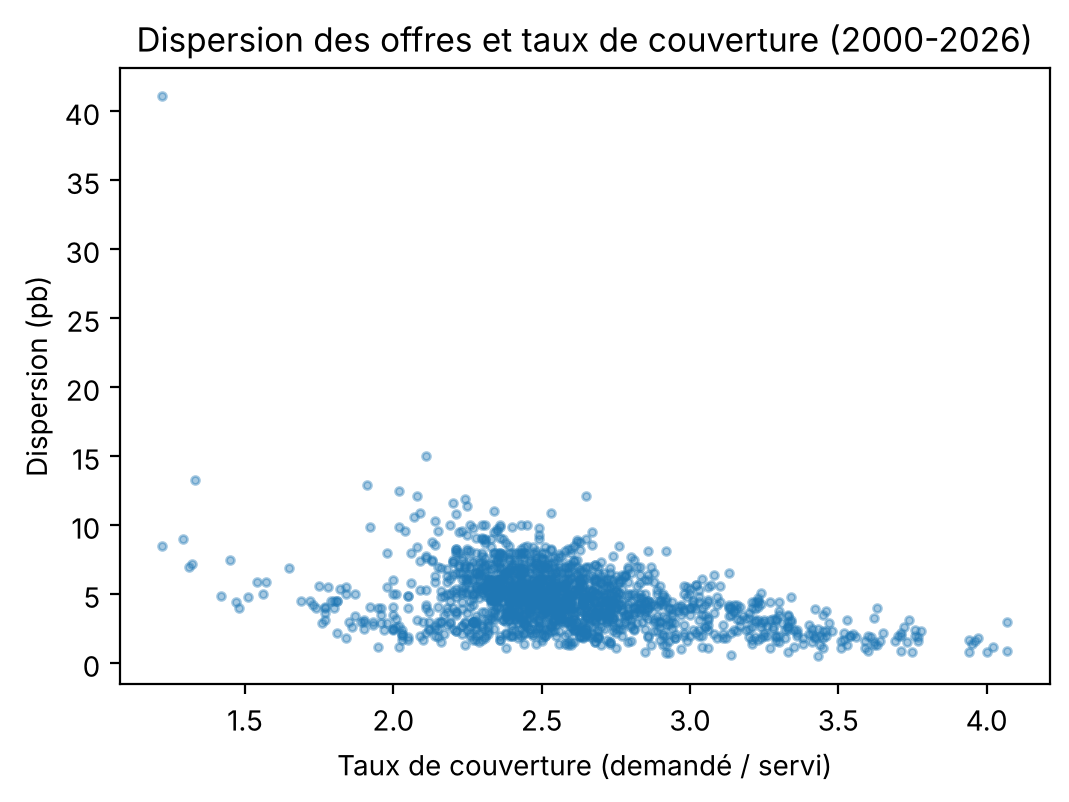

Corrélation de rang, toute la période  : -0.36
Corrélation de rang, à année donnée    : -0.62


In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(d2000["couverture"], d2000["dispersion_pb"], s=8, alpha=0.4)
ax.set(title="Dispersion des offres et taux de couverture (2000-2026)",
       xlabel="Taux de couverture (demandé / servi)", ylabel="Dispersion (pb)")
plt.show()

d2000["dispersion_ecart"] = analyse.ecart_a_l_annee(d2000, "dispersion_pb")
d2000["couverture_ecart"] = analyse.ecart_a_l_annee(d2000, "couverture")
print("Corrélation de rang, toute la période  :", round(analyse.correlation_rangs(d2000["couverture"], d2000["dispersion_pb"]), 2))
print("Corrélation de rang, à année donnée    :", round(analyse.correlation_rangs(d2000["couverture_ecart"], d2000["dispersion_ecart"]), 2))

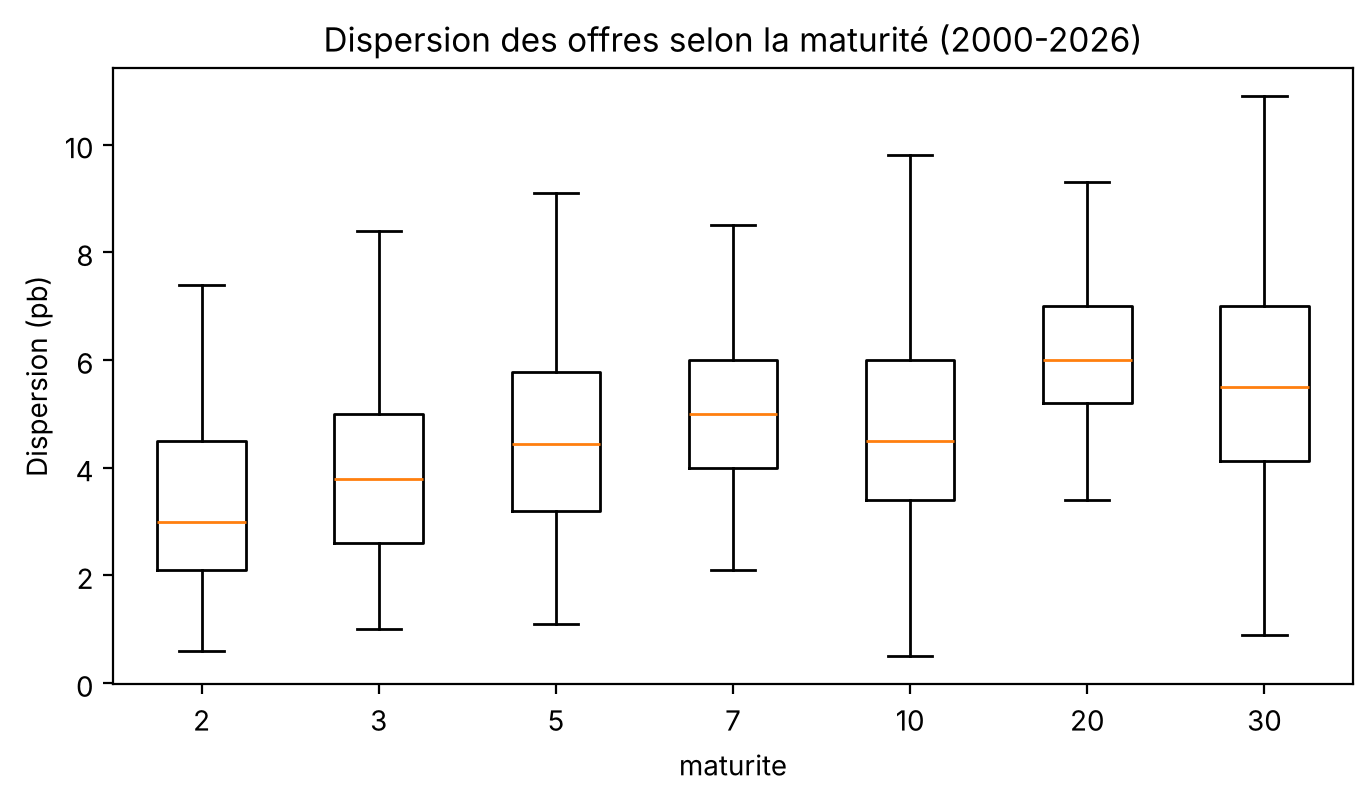

dispersion_pb                    couverture                   
                 count  mean median   std      count  mean median   std
maturite                                                               
2                  310  3.40   3.00  1.59        310  2.71   2.65  0.52
3                  231  3.93   3.80  1.69        231  2.81   2.71  0.42
5                  294  4.59   4.45  1.86        294  2.47   2.46  0.30
7                  223  5.19   5.00  1.55        223  2.55   2.53  0.19
10                 279  4.97   4.50  3.04        279  2.55   2.53  0.35
20                  78  6.13   6.00  1.59         78  2.56   2.55  0.17
30                 226  5.76   5.50  2.22        226  2.40   2.38  0.24

In [9]:
analyse.graphique_par_groupe(d2000, "dispersion_pb", "maturite",
                             "Dispersion des offres selon la maturité (2000-2026)", "Dispersion (pb)")
analyse.tableau_par_groupe(d2000, "maturite", ["dispersion_pb", "couverture"])

> **À rédiger (Diego)**. Points clés à transformer en texte :
>
> - le taux le plus bas est inutilisable : l'écart limite - plus bas a un écart-type plus de 10 fois plus grand que la dispersion, avec des valeurs absurdes (une seule offre isolée suffit) ;
> - dispersion et couverture vont en sens inverse : corrélation de rang de -0,36, et -0,62 à année donnée ; c'est ce qu'on attend d'un indicateur de qualité ;
> - réserve : ce lien est en partie mécanique (les deux indicateurs décrivent les mêmes offres) ;
> - la dispersion augmente avec la maturité : environ 3 pb pour le 2 ans, 5,5 à 6 pb pour les 20 et 30 ans (les titres longs sont plus difficiles à évaluer) ; donc attention à comparer des groupes de maturités différentes.

## 5. Résultats

### 5.1 Comment les adjudications ont évolué depuis 1979

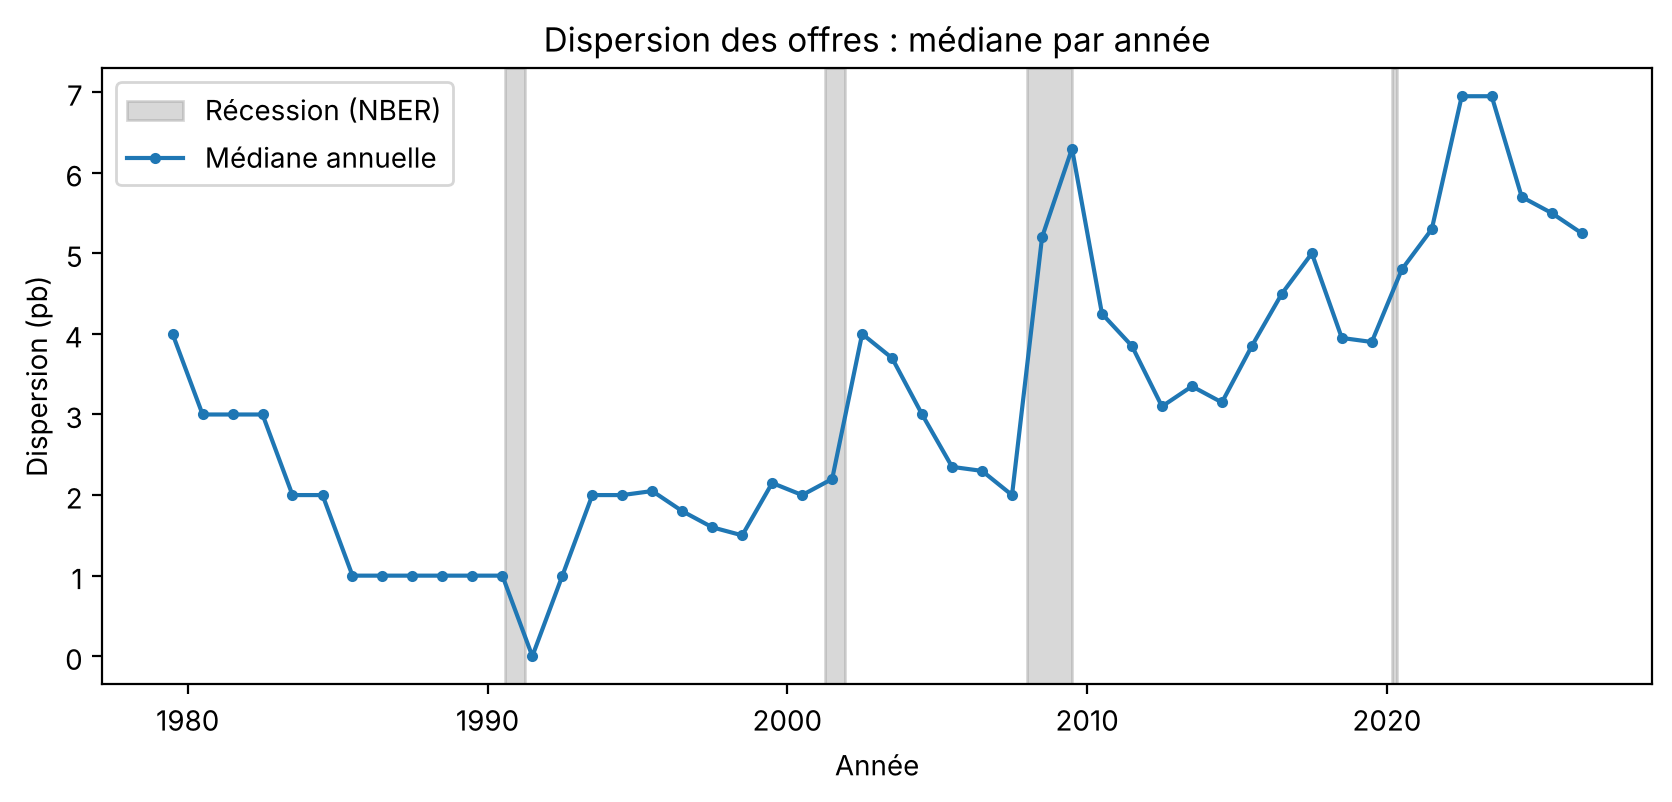

In [10]:
analyse.graphique_evolution(table, "dispersion_pb", "Dispersion des offres : médiane par année",
                            "Dispersion (pb)", marche)

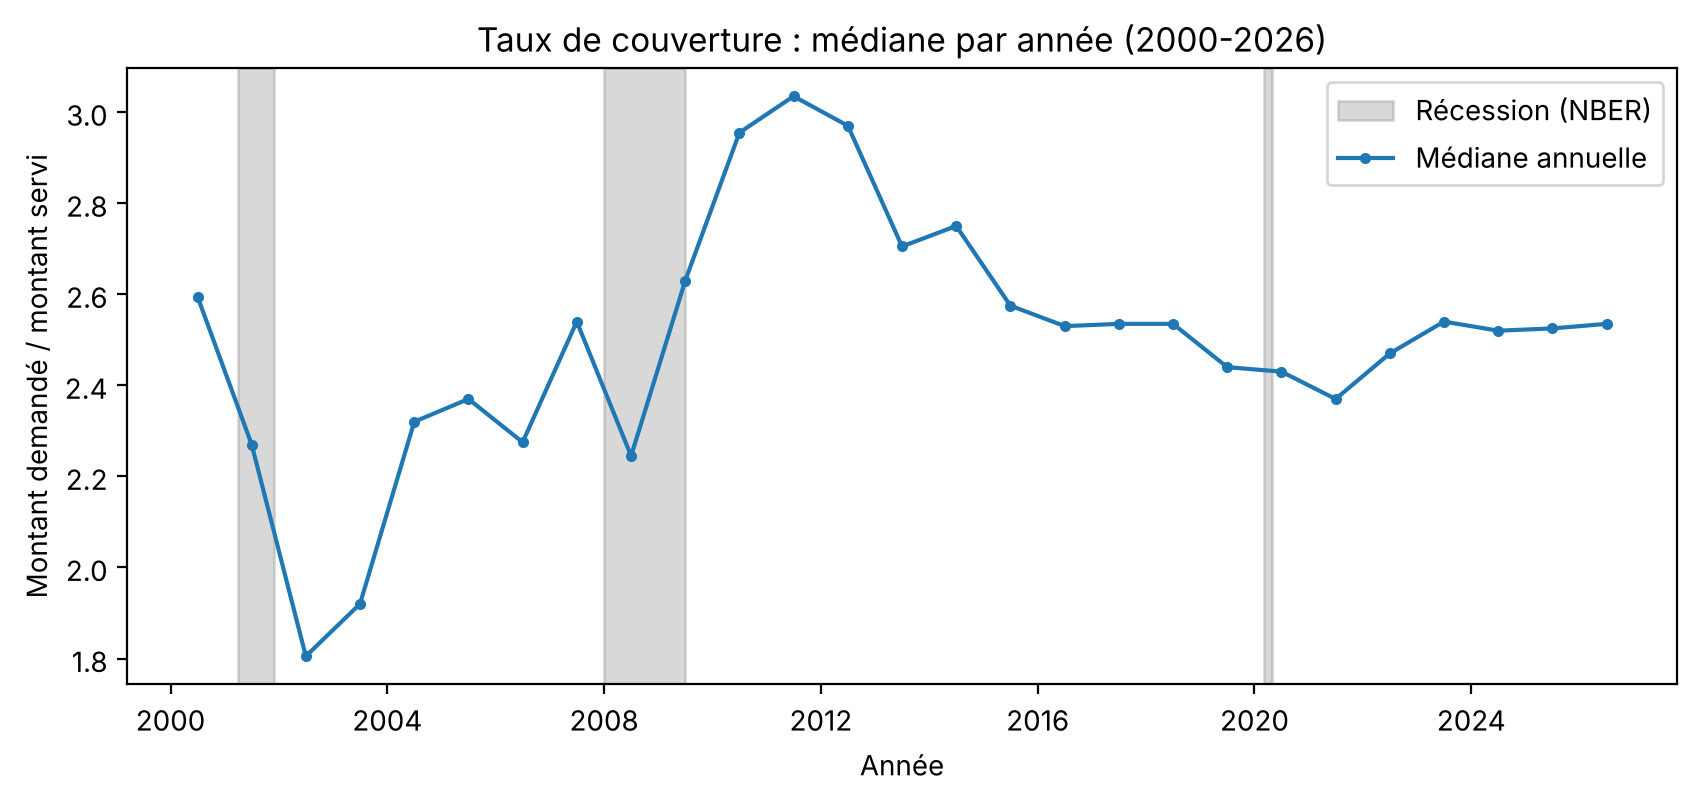

In [11]:
analyse.graphique_evolution(d2000, "couverture", "Taux de couverture : médiane par année (2000-2026)",
                            "Montant demandé / montant servi", marche)

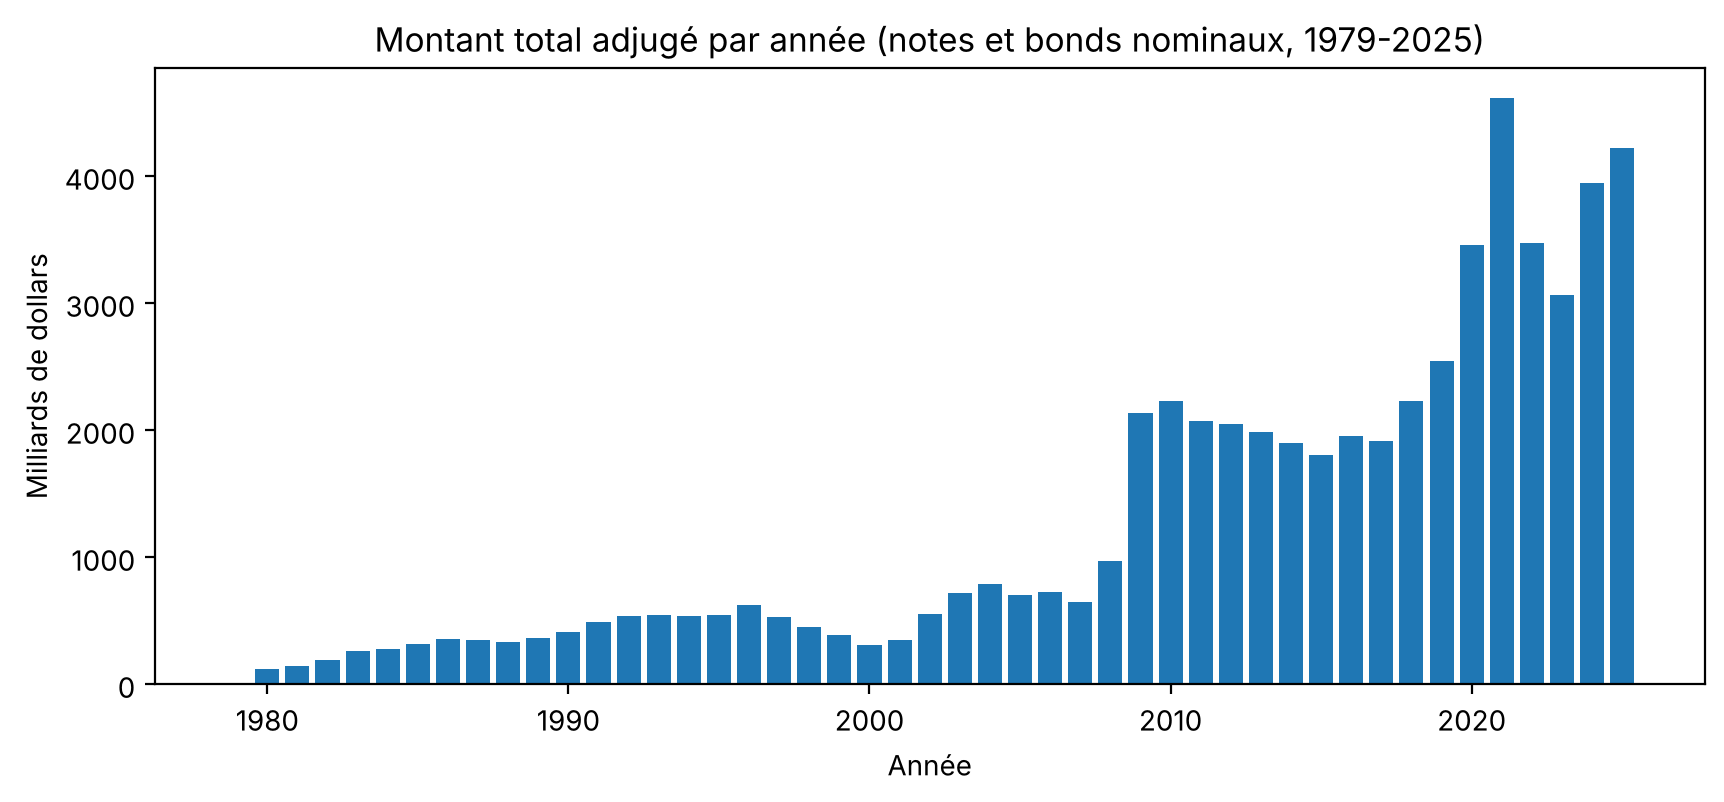

In [12]:
volumes = table[table["annee"] <= 2025].groupby("annee")["montant"].sum() / 1e9
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(volumes.index, volumes.values)
ax.set(title="Montant total adjugé par année (notes et bonds nominaux, 1979-2025)",
       xlabel="Année", ylabel="Milliards de dollars")
plt.show()

> **À rédiger (Diego)**. Points clés à transformer en texte :
>
> - dispersion : environ 3 pb au début des années 1980, puis 1 pb à la fin des années 1980 (taux arrondis, taux moyen et non médian) ; 2 à 3 pb de 1998 à 2007 ; puis plus élevée depuis 2008, avec deux pics : 2008-2009 (6,3 pb) et 2022-2023 (7 pb) ;
> - le pic de 2022-2023 n'est pas une récession : c'est la hausse très rapide des taux de la Fed ;
> - la couverture est plus stable (entre 1,8 et 3), au plus haut en 2010-2012 ;
> - les montants adjugés ont été multipliés par plus de 6 entre 2007 et 2025 (646 à 4 223 milliards), avec des sauts en 2009 et 2020-2021 : en récession, la demande pour les titres sûrs monte, mais l'offre de titres aussi ;
> - les récessions de 1980-1982 ne sont pas grisées : le VIX (et donc notre table marché) commence en 1990.

### 5.2 Qui achète la dette américaine ?

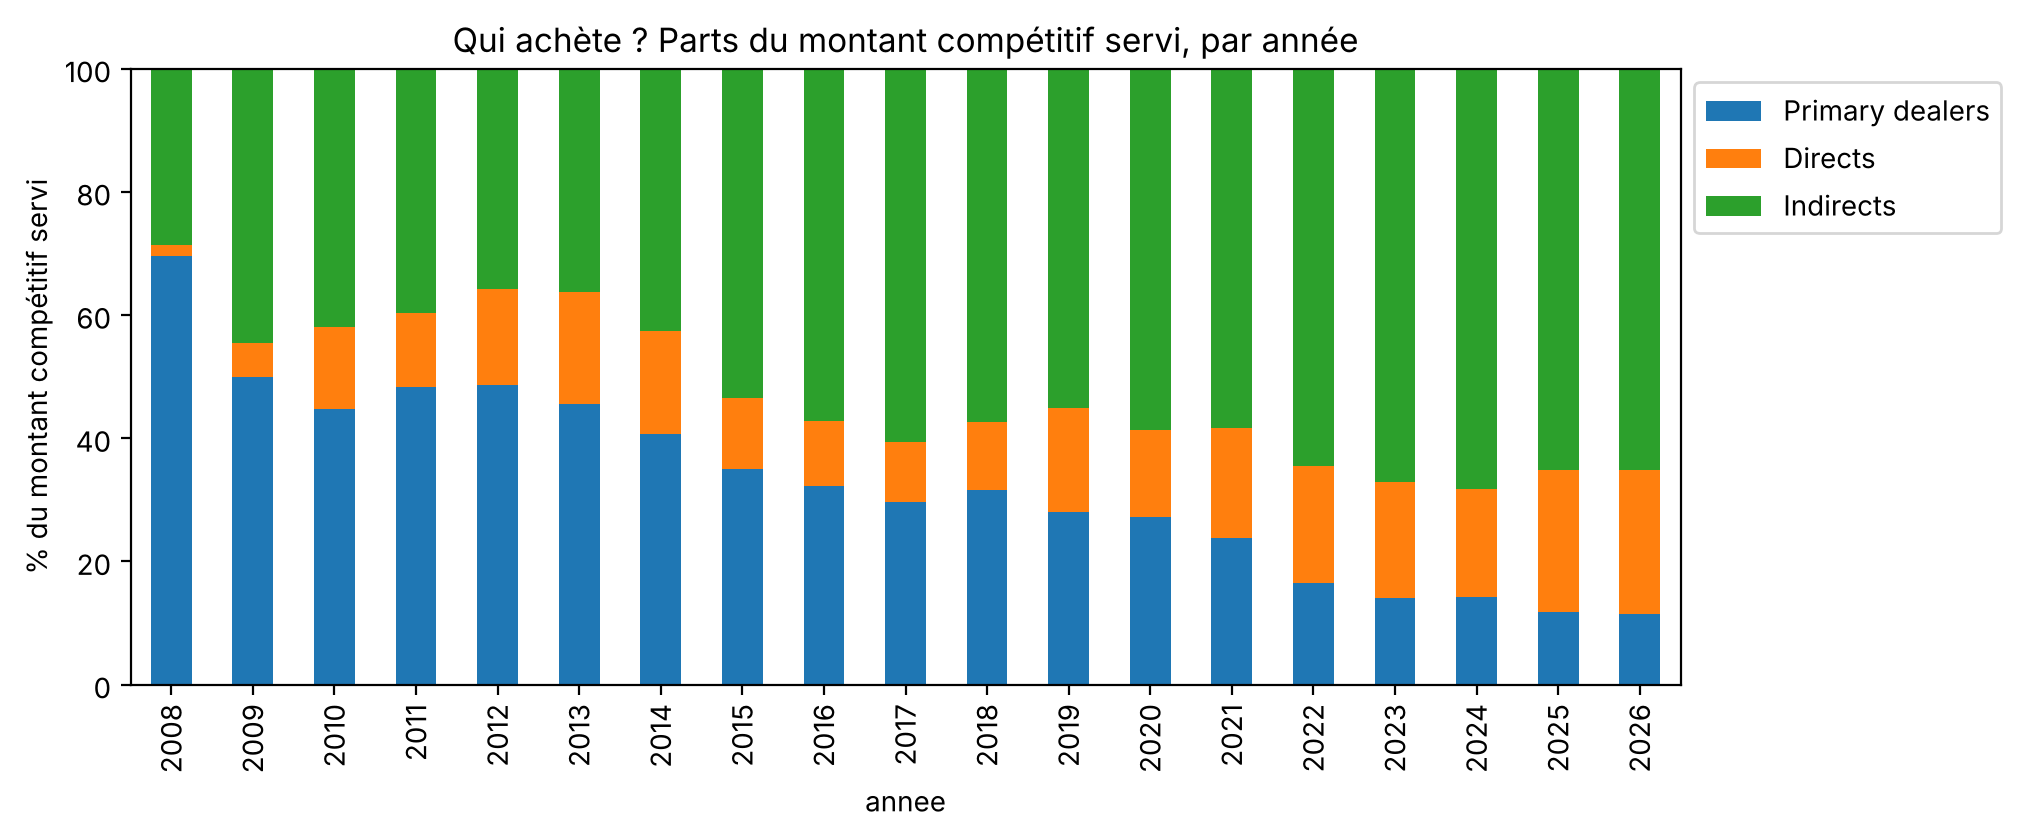

In [13]:
analyse.graphique_parts(table, "annee", "Qui achète ? Parts du montant compétitif servi, par année")

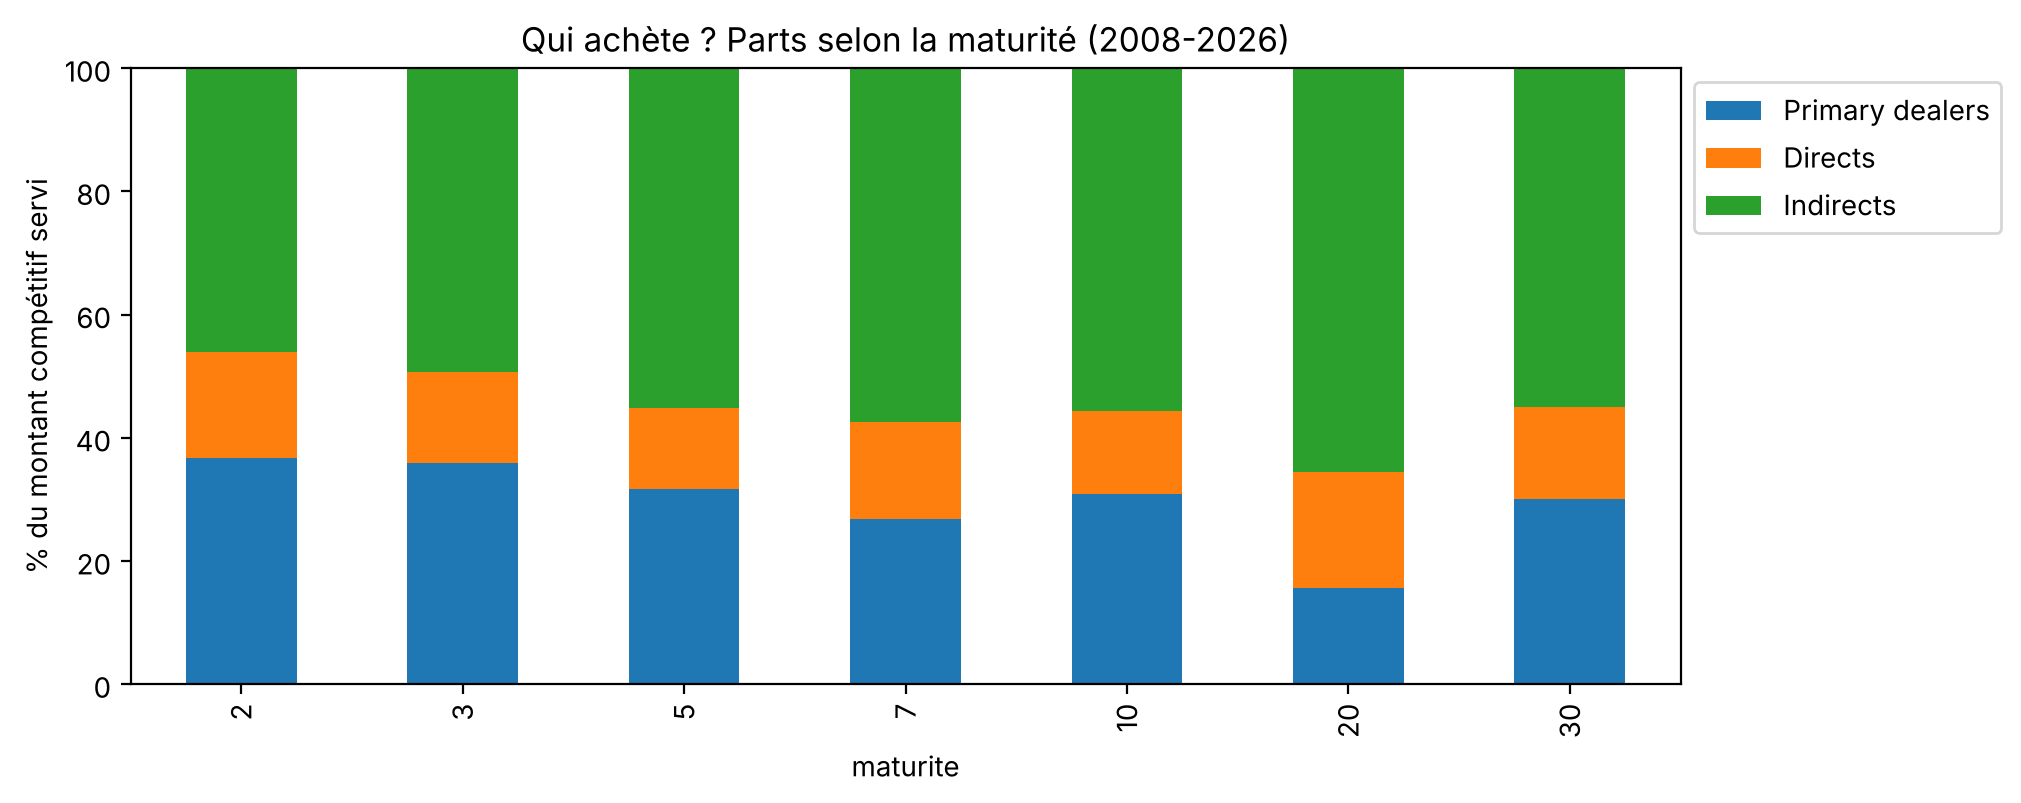

In [14]:
analyse.graphique_parts(table, "maturite", "Qui achète ? Parts selon la maturité (2008-2026)")

In [15]:
avec_parts = table.dropna(subset=["part_indirects"]).copy()
print("Part des indirects et dispersion, toute la période :",
      round(analyse.correlation_rangs(avec_parts["part_indirects"], avec_parts["dispersion_pb"]), 2))
print("Part des indirects et dispersion, à année donnée   :",
      round(analyse.correlation_rangs(analyse.ecart_a_l_annee(avec_parts, "part_indirects"),
                                      analyse.ecart_a_l_annee(avec_parts, "dispersion_pb")), 2))

Part des indirects et dispersion, toute la période : 0.37
Part des indirects et dispersion, à année donnée   : 0.12


> **À rédiger (Allan)**. Points clés à transformer en texte :
>
> - les trois types : primary dealers (26 grandes banques désignées par la Fed de New York, tenues d'enchérir à chaque adjudication), directs (offres en nom propre), indirects (via un intermédiaire, dont les banques centrales étrangères) ;
> - changement le plus net de la base : dealers 70 % en 2008 -> 11 % en 2026 ; indirects 29 % -> 65 % ; directs 2 % -> 23 % ;
> - une forte part des dealers est lue comme un signe d'adjudication faible (ils absorbent ce que les autres ne veulent pas) ;
> - par maturité : indirects plus présents sur le long (65 % sur le 20 ans) que sur le 2 ans (46 %), mais le 20 ans n'a été relancé qu'en mai 2020, à une période où la part des indirects était déjà haute ;
> - piège : sur toute la période, part des indirects et dispersion sont liées (+0,37), mais presque plus à année donnée (+0,12) : les deux ont simplement augmenté en même temps.

### 5.3 Les adjudications se passent-elles moins bien en période de stress ?

In [2]:
analyse.graphique_par_groupe(d2000, "dispersion_pb", "stress",
                             "Dispersion des offres selon le stress de la veille (2000-2026)",
                             "Dispersion (pb)", ordre=["bas", "moyen", "haut"])
analyse.tableau_par_groupe(d2000, "stress", ["dispersion_pb", "dispersion_ecart", "couverture", "couverture_ecart"])

NameError: name 'analyse' is not defined

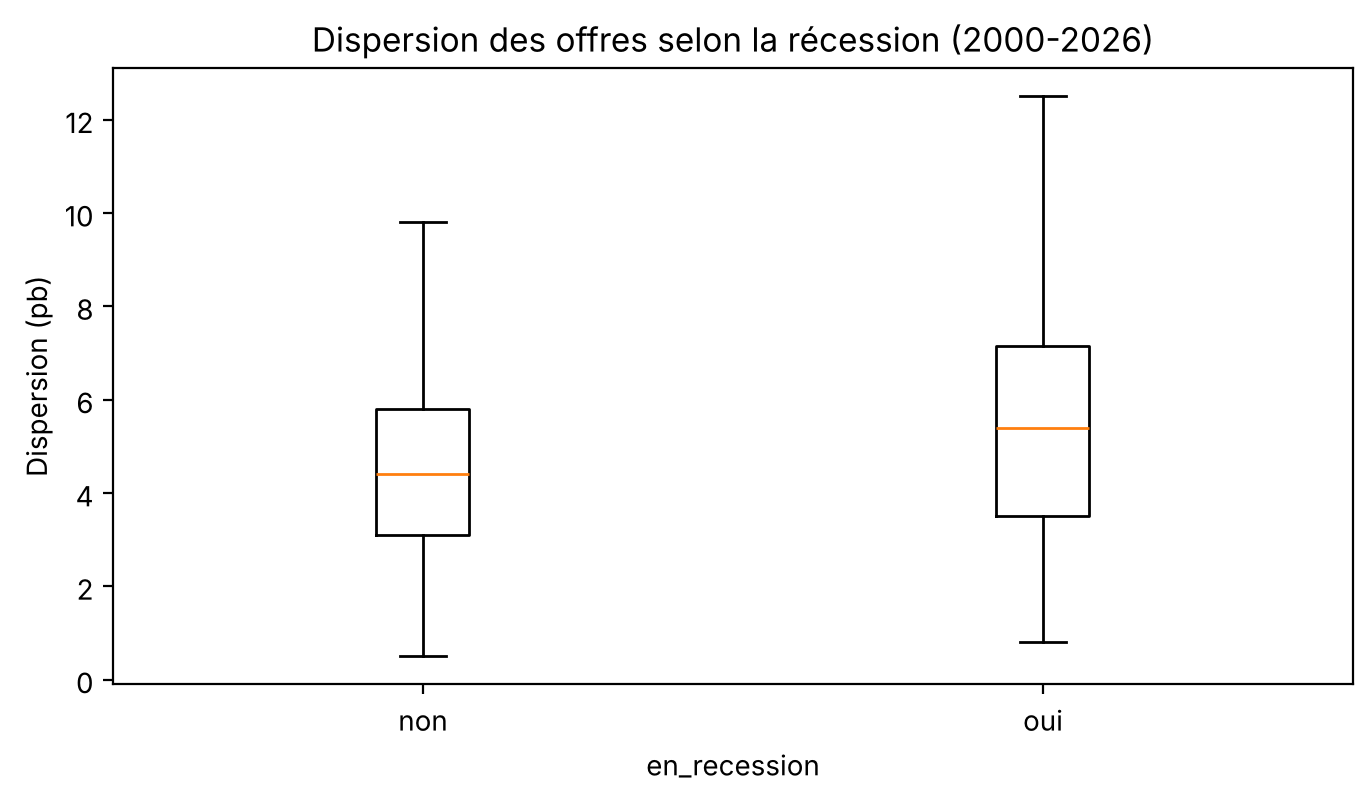

dispersion_pb                    dispersion_ecart               \
                     count  mean median   std            count  mean median   
en_recession                                                                  
non                   1538  4.57    4.4  1.95             1538  0.11    0.0   
oui                    103  5.88    5.4  4.44              103  0.84    0.2   

                   couverture                    couverture_ecart        \
               std      count  mean median   std            count  mean   
en_recession                                                              
non           1.47       1538  2.60   2.54  0.38             1538  0.04   
oui           4.26        103  2.35   2.33  0.32              103 -0.05   

                           
             median   std  
en_recession               
non            0.00  0.29  
oui           -0.04  0.31

In [ ]:
d2000["en_recession"] = d2000["recession"].map({0: "non", 1: "oui"})
analyse.graphique_par_groupe(d2000, "dispersion_pb", "en_recession",
                             "Dispersion des offres selon la récession (2000-2026)",
                             "Dispersion (pb)", ordre=["non", "oui"])
analyse.tableau_par_groupe(d2000, "en_recession", ["dispersion_pb", "dispersion_ecart", "couverture", "couverture_ecart"])


-  Notons des observations importantes concernant la couverture et la dispersion relativement au VIX et aux récessions. Avant toute chose, il faut souligner qu'on prend le stress de la veille, car le le VIX du jour réagit déjà au résultat de l'adjudication

- La dispersion médiane s'établit à 4,0 points de base en stress bas, 4,5 pb en moyen et 5,1 pb en haut : les offres sont plus dispersées quand les marchés ont peur. Néanmoins, à année donnée comme il y a plusieurs adjudications au cours d'une année, l'effet reste mais devient faible. Les médianes sont proches de 0, la moyenne est d'environ +0,4 pb en stress haut, tirée par quelques adjudications extrêmes comme celles de mars 2020. Considérons désormais la dispersions en cas de récession : la dispersion médiane est de 5,4 pb contre 4,4 pb, le contraste est manifeste. Il faut toutefois apporter une lecture prudente à cette observation, car nous ne disposons que de 103 adjudications sur 3 épisodes (2001, 2008-2009, 2020)

- Concernant la couverture, elle ne bouge presque pas avec le stress : la demande en volume ne recule pas, puisque - à l'inverse des actions du S&P 500 - les obligations du trésor américain sont davantage vues comme une valeur refuge. En revanche la couverture un peu plus basse en récession (2,33 contre 2,54), mais l'écart disparaît presque à année donnée. En effet, l'écart de couverture en temps de récession est poussé en grande partie par l'explosion d'émissions ce qui fait mécaniquement baisser le bid-to-cover.

## 6. Limites

> **À rédiger (tous)**. Points clés à transformer en texte :
>
> - les offres individuelles ne sont pas publiques : on ne voit que trois points de la distribution des offres ;
> - le point du milieu change de définition en 1998 (moyenne puis médiane) ;
> - le lien dispersion / couverture est en partie mécanique ;
> - les tendances de long terme peuvent créer de fausses corrélations ; comparer à année donnée aide mais ne règle pas tout ;
> Une limite qu'il convient de souligner est le peu de récessions que nous avons pu analyser, à savoir 3 épisodes depuis 2000 qui ne comprennent que 103 adjudications. En outre, le  VIX est un outil quelque peu récent, publié pour la première fois en 1993 par la CBOE.
> - on décrit des liens, on n'estime aucun effet causal.

## 7. Conclusion

> **À rédiger (Diego, à écrire en dernier)**. Points clés à transformer en texte :
>
> - la réponse à la question en 3-4 phrases, avec des chiffres : la dispersion est un bon indicateur ; les acheteurs ont changé ; le stress disperse un peu les offres sans faire reculer la demande.

## Sources

- Trésor américain, [Treasury Securities Auctions Data](https://fiscaldata.treasury.gov/datasets/treasury-securities-auctions-data/)
- CBOE, [VIX Historical Data](https://www.cboe.com/tradable_products/vix/vix_historical_data/)
- NBER, [US Business Cycle Expansions and Contractions](https://www.nber.org/research/data/us-business-cycle-expansions-and-contractions)
- Fed de New York, [liste des primary dealers](https://www.newyorkfed.org/markets/primarydealers)
- Fed de New York, [How Liquid Is the New 20-Year Treasury Bond?](https://libertystreeteconomics.newyorkfed.org/2020/07/how-liquid-is-the-new-20-year-treasury-bond/)